# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [1]:
%pip install numpy pandas matplotlib scikit-learn ipykernel

   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
    --------------------------------------- 0.3/12.7 MB ? eta -:--:--
    --------------------------------------- 0.3/12.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.7 MB 485.9 kB/s eta 0:00:26
   - -------------------------------------- 0.5/12.7 MB 485.9 kB/s eta 0:00:26
   - -------------------------------------- 0.5/12.7 MB 485.9 kB/s eta 0:00:26
   -- ------------------------------------- 0.8/12.7 MB 462.6 kB/s eta 0:00:26
   -- ------------------------------------- 0.8/12.7 MB 462.6 kB/s eta 0:00:26
   -- ------------------------------------- 0.8/12.7 MB 462.6 kB/s eta 0:00:26
   --- ------------------------------------ 1.0/12.7 MB 472.8 kB/s eta 0:00:25
   --- --------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Dimensiones de la matriz de características (X): (150, 4)
Dimensiones del vector de etiquetas (y): (150,)
Número de instancias: 150
Número de características: 4
Nombres de características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nombres de clases: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Distribución de ejemplos por clase:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

--- Primeros 5 ejemplos del dataset ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


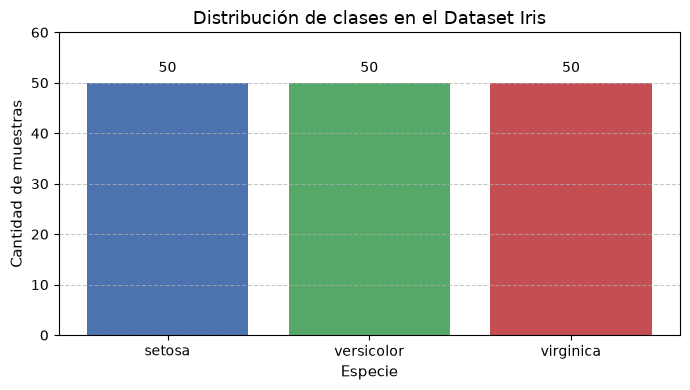

In [2]:
# Aquí cumple con el primer paso
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris

# 1. Cargar el dataset Iris
iris = load_iris(as_frame=True)
df = iris.frame

# Separación de matriz de características X y vector de etiquetas y
X = iris.data
y = iris.target

# 2. Desplegar dimensiones y metadatos
print(f"Dimensiones de la matriz de características (X): {X.shape}")
print(f"Dimensiones del vector de etiquetas (y): {y.shape}")
print(f"Número de instancias: {X.shape[0]}")
print(f"Número de características: {X.shape[1]}")
print(f"Nombres de características: {list(iris.feature_names)}")
print(f"Nombres de clases: {list(iris.target_names)}")
print("\nDistribución de ejemplos por clase:")
print(df["target"].map(dict(enumerate(iris.target_names))).value_counts())

# 3. Mostrar tabla con 5 ejemplos
print("\n--- Primeros 5 ejemplos del dataset ---")
display(df.head())

# 4. Gráfico de distribución de clases
counts = df["target"].map(dict(enumerate(iris.target_names))).value_counts()

plt.figure(figsize=(7, 4))
bars = plt.bar(counts.index, counts.values, color=["#4C72B0", "#55A868", "#C44E52"])
plt.title("Distribución de clases en el Dataset Iris", fontsize=13)
plt.xlabel("Especie", fontsize=11)
plt.ylabel("Cantidad de muestras", fontsize=11)
plt.ylim(0, 60)

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 1.5,
      int(yval),
      ha="center",
      va="bottom",
  )

plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.


Instancias -> Train: 90, Val: 30, Test: 30

--- Resultados en el conjunto de Validación ---


,Modelo,Acc Val,F1 Val
0,Gaussian Naive Bayes,0.9333,0.9333
1,Regresión Logística,0.9333,0.9333
2,SVM lineal,0.9333,0.9333
3,Árbol de Decisión,0.9000,0.8997
4,Random Forest,0.9333,0.9333
5,Gradient Boosting,0.9000,0.8997
6,MLP Clasificador,0.9333,0.9333



--- Tabla Final de Resultados en Prueba ---


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,Var smoothing=1e-9,0.9333,0.9333
1,Regresión Logística,StandardScaler,"C=1.0, solver=lbfgs",0.9333,0.9333
2,SVM lineal,StandardScaler,"kernel=linear, C=1.0",0.9333,0.9333
3,Árbol de Decisión,StandardScaler,"max_depth=3, min_samples_split=4",0.9333,0.9333
4,Random Forest,StandardScaler,"n_estimators=50, max_depth=3",0.9333,0.9333
5,Gradient Boosting,StandardScaler,"n_estimators=30, lr=0.1",0.9333,0.9333
6,MLP Clasificador,StandardScaler,"hidden_layers=(16, 8), relu, max_iter=1000",0.9333,0.9333


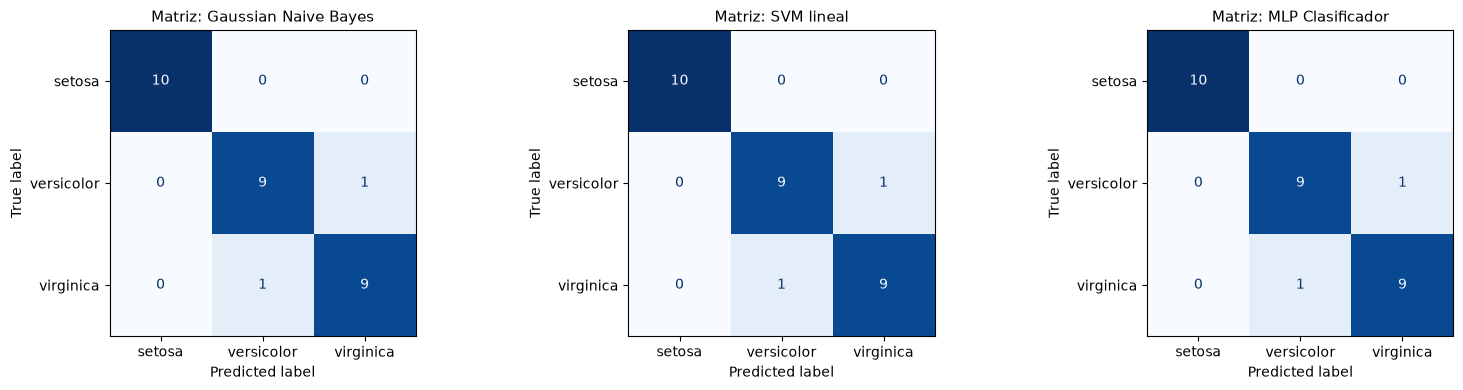


Total de errores en SVM en Test: 2 de 30 muestras.

Instancia Test Índice 23:
  Características reales: {'sepal length (cm)': np.float64(6.1), 'sepal width (cm)': np.float64(2.6), 'petal length (cm)': np.float64(5.6), 'petal width (cm)': np.float64(1.4)}
  Clase Real: virginica | Predicción SVM: versicolor

Instancia Test Índice 25:
  Características reales: {'sepal length (cm)': np.float64(6.7), 'sepal width (cm)': np.float64(3.0), 'petal length (cm)': np.float64(5.0), 'petal width (cm)': np.float64(1.7)}
  Clase Real: versicolor | Predicción SVM: virginica


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Carga y partición de datos: 60% Train, 20% Val, 20% Test (estratificado)
iris = load_iris()
X, y = iris.data, iris.target

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print(
    f"Instancias -> Train: {len(y_train)}, Val: {len(y_val)}, Test:"
    f" {len(y_test)}"
)

# 2. Definición de modelos en Pipeline (estandarización incluida)
model_configs = {
    "Gaussian Naive Bayes": (
        Pipeline([("scaler", StandardScaler()), ("clf", GaussianNB())]),
        "Var smoothing=1e-9",
    ),
    "Regresión Logística": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(C=1.0, max_iter=500, random_state=42)),
        ]),
        "C=1.0, solver=lbfgs",
    ),
    "SVM lineal": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="linear", C=1.0, random_state=42)),
        ]),
        "kernel=linear, C=1.0",
    ),
    "Árbol de Decisión": (
        Pipeline([
            ("scaler", StandardScaler()),
            (
                "clf",
                DecisionTreeClassifier(
                    max_depth=3, min_samples_split=4, random_state=42
                ),
            ),
        ]),
        "max_depth=3, min_samples_split=4",
    ),
    "Random Forest": (
        Pipeline([
            ("scaler", StandardScaler()),
            (
                "clf",
                RandomForestClassifier(
                    n_estimators=50, max_depth=3, random_state=42
                ),
            ),
        ]),
        "n_estimators=50, max_depth=3",
    ),
    "Gradient Boosting": (
        Pipeline([
            ("scaler", StandardScaler()),
            (
                "clf",
                GradientBoostingClassifier(
                    n_estimators=30, learning_rate=0.1, random_state=42
                ),
            ),
        ]),
        "n_estimators=30, lr=0.1",
    ),
    "MLP Clasificador": (
        Pipeline([
            ("scaler", StandardScaler()),
            (
                "clf",
                MLPClassifier(
                    hidden_layer_sizes=(16, 8),
                    activation="relu",
                    max_iter=1000,
                    random_state=42,
                ),
            ),
        ]),
        "hidden_layers=(16, 8), relu, max_iter=1000",
    ),
}

# 3. Fase de Entrenamiento y Validación
val_records = []
for name, (pipeline, params) in model_configs.items():
  pipeline.fit(X_train, y_train)
  y_val_pred = pipeline.predict(X_val)
  acc_val = accuracy_score(y_val, y_val_pred)
  f1_val = f1_score(y_val, y_val_pred, average="macro")
  val_records.append({
      "Modelo": name,
      "Acc Val": round(acc_val, 4),
      "F1 Val": round(f1_val, 4),
  })

df_val = pd.DataFrame(val_records)
print("\n--- Resultados en el conjunto de Validación ---")
display(df_val)

# 4. Evaluación Final en Test (configuraciones congeladas)
test_results = []
trained_models = {}

for name, (pipeline, params) in model_configs.items():
  # Entrenado con Train, evaluado directamente en Test
  y_test_pred = pipeline.predict(X_test)
  acc_test = accuracy_score(y_test, y_test_pred)
  f1_test = f1_score(y_test, y_test_pred, average="macro")

  test_results.append({
      "Modelo": name,
      "Transformación": "StandardScaler",
      "Hiperparámetros principales": params,
      "Accuracy de prueba": round(acc_test, 4),
      "F1 macro de prueba": round(f1_test, 4),
  })
  trained_models[name] = pipeline

df_test = pd.DataFrame(test_results)
print("\n--- Tabla Final de Resultados en Prueba ---")
display(df_test)

# 5. Matrices de confusión para Naive Bayes, SVM y MLP
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
selected_models = [
    ("Gaussian Naive Bayes", axes[0]),
    ("SVM lineal", axes[1]),
    ("MLP Clasificador", axes[2]),
]

for name, ax in selected_models:
  pipe = trained_models[name]
  y_pred = pipe.predict(X_test)
  ConfusionMatrixDisplay.from_predictions(
      y_test,
      y_pred,
      display_labels=iris.target_names,
      ax=ax,
      cmap="Blues",
      colorbar=False,
  )
  ax.set_title(f"Matriz: {name}", fontsize=11)

plt.tight_layout()
plt.show()

# 6. Inspección de Errores de Clasificación en el conjunto de prueba (SVM vs Real)
svm_pipeline = trained_models["SVM lineal"]
y_test_pred_svm = svm_pipeline.predict(X_test)
errors_idx = np.where(y_test != y_test_pred_svm)[0]

print(
    f"\nTotal de errores en SVM en Test: {len(errors_idx)} de {len(y_test)}"
    " muestras."
)
if len(errors_idx) > 0:
  for idx in errors_idx[:2]:
    print(f"\nInstancia Test Índice {idx}:")
    print(f"  Características reales: {dict(zip(iris.feature_names, X_test[idx]))}")
    print(
        f"  Clase Real: {iris.target_names[y_test[idx]]} | Predicción SVM:"
        f" {iris.target_names[y_test_pred_svm[idx]]}"
    )


## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?